# MedNet paper reproduction — three datasets (improved original notebook)

**BloodMNIST, OCTMNIST, DermaMNIST** | Full official test sets | Larger stratified OCT training | CBAM vs no-CBAM | DermaMNIST class analysis

This notebook retains the original architecture, dataset examples, training curves, confusion matrices, ROC, prediction examples and five-stage Grad-CAM. It adds four stronger reproduction experiments. **Published paper results are reference values, not your own results.**

## Cell 1 — Install MedMNIST (only once)

In [37]:
!pip -q install medmnist

## Cell 2 — Imports and experiment settings
The full official test split is always used. Set `RUN_TRAINING=False` for the CPU speed check, then change to `True` to train. Six runs (three datasets × two variants) may take many hours on Kaggle CPU. Check the benchmark first.

In [38]:
DATASETS = ['bloodmnist', 'octmnist', 'dermamnist']

IMAGE_SIZE = 64
BATCH_SIZE = 32
EPOCHS = 20
PATIENCE = 10
SEED = 42
RUN_TRAINING = True

DATA_PATH = '/kaggle/input/datasets/zubairiqbal10'

TRAIN_LIMITS = {
    'bloodmnist': None,
    'octmnist': None,
    'dermamnist': None
}

VAL_LIMITS = {
    'bloodmnist': None,
    'octmnist': None,
    'dermamnist': None
}

VARIANTS = {
    'CBAM': True,
    'No_CBAM': False
}

DEVICE = torch.device(
    'cuda:0' if torch.cuda.is_available() else 'cpu'
)

OUTPUT_DIR = '/kaggle/working/mednet_64_results'

os.makedirs(OUTPUT_DIR, exist_ok=True)

print('Device:', DEVICE)
print('Image size:', IMAGE_SIZE)
print('Batch size:', BATCH_SIZE)
print('Epochs:', EPOCHS)

Device: cuda:0
Image size: 64
Batch size: 32
Epochs: 20


## Cell 3 — Download and check all three datasets\nUses `ds.imgs` (not `ds.images`), fixing the earlier AttributeError. Class names come from MedMNIST metadata, so there is no missing `CLASS_NAMES` variable.

In [39]:
all_data = {}

for name in DATASETS:

    info = INFO[name]

    file_path = os.path.join(
        DATA_PATH,
        name,
        name + '_64.npz'
    )

    if not os.path.exists(file_path):
        raise FileNotFoundError(file_path)

    splits = {}

    with np.load(file_path) as data:

        for split in ['train', 'val', 'test']:

            images = data[split + '_images']
            labels = data[split + '_labels'].reshape(-1)

            assert images.shape[1:3] == (64, 64)
            assert len(images) == len(labels)

            splits[split] = (images, labels)

    class_names = [
        info['label'][str(i)]
        for i in range(len(info['label']))
    ]

    all_data[name] = {
        'splits': splits,
        'names': class_names
    }

    print('\nDataset:', name)
    print('File:', file_path)
    print('Classes:', len(class_names))

    for split, (images, labels) in splits.items():
        print(split, images.shape, labels.shape)

    print('Labels:', class_names)


Dataset: bloodmnist
File: /kaggle/input/datasets/zubairiqbal10/bloodmnist/bloodmnist_64.npz
Classes: 8
train (11959, 64, 64, 3) (11959,)
val (1712, 64, 64, 3) (1712,)
test (3421, 64, 64, 3) (3421,)
Labels: ['basophil', 'eosinophil', 'erythroblast', 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']

Dataset: octmnist
File: /kaggle/input/datasets/zubairiqbal10/octmnist/octmnist_64.npz
Classes: 4
train (97477, 64, 64) (97477,)
val (10832, 64, 64) (10832,)
test (1000, 64, 64) (1000,)
Labels: ['choroidal neovascularization', 'diabetic macular edema', 'drusen', 'normal']

Dataset: dermamnist
File: /kaggle/input/datasets/zubairiqbal10/dermamnist/dermamnist_64.npz
Classes: 7
train (7007, 64, 64, 3) (7007,)
val (1003, 64, 64, 3) (1003,)
test (2005, 64, 64, 3) (2005,)
Labels: ['actinic keratoses and intraepithelial carcinoma', 'basal cell carcinoma', 'benign keratosis-like lesions', 'dermatofibroma', 'melanoma', 'melanocyt

## Cell 4 — Show example images (all datasets)

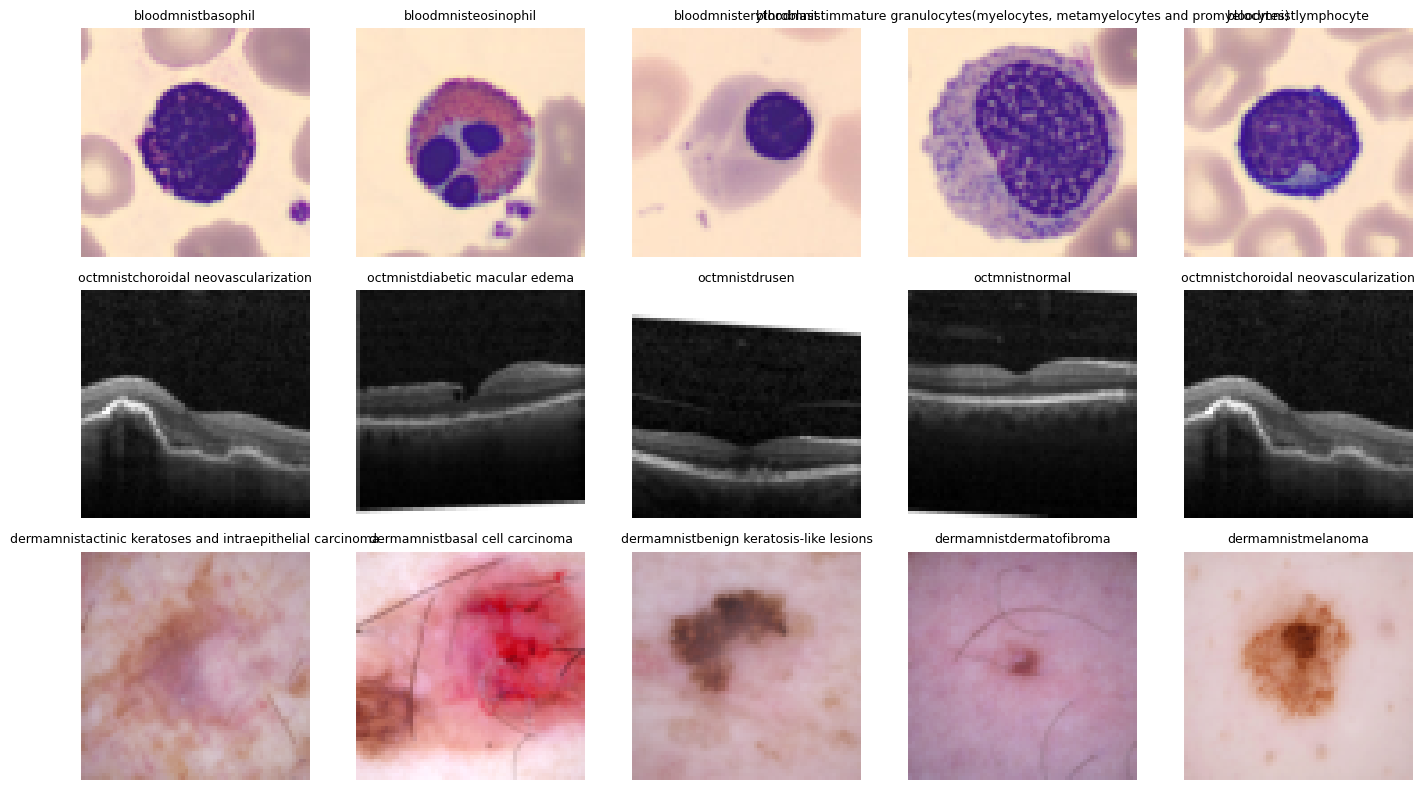

In [40]:
fig, axes = plt.subplots(3, 5, figsize=(14, 8))
for row, name in enumerate(DATASETS):
    images, labels = all_data[name]['splits']['train']
    names = all_data[name]['names']
    for col in range(5):
        class_id = col % len(names)
        idx = np.flatnonzero(labels == class_id)[0]
        axes[row, col].imshow(images[idx], cmap='gray' if images[idx].ndim == 2 else None)
        axes[row, col].set_title(name + '\
' + names[class_id], fontsize=9)
        axes[row, col].axis('off')
plt.tight_layout(); plt.show()

## Cell 5 — Dataset and DataLoader
Use class-stratified subsets for training and validation, but **never subset the official test data**. OCT grayscale is repeated to three channels for the original MedNet input.

In [41]:
class SimpleMedDataset(Dataset):
    def __init__(self, images, labels, indices=None):
        if indices is not None:
            images, labels = images[indices], labels[indices]
        self.images, self.labels = images, labels.reshape(-1)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        image = self.images[idx]
        if image.ndim == 2:
            image = np.repeat(image[:, :, None], 3, axis=2)
        x = torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1))).float() / 255.0
        return (x - 0.5) / 0.5, int(self.labels[idx])

def stratified_indices(labels, limit, seed=SEED):
    labels = np.asarray(labels).reshape(-1)
    if limit is None or limit >= len(labels):
        return np.arange(len(labels))
    rng = np.random.default_rng(seed)
    classes, counts = np.unique(labels, return_counts=True)
    if limit < len(classes):
        raise ValueError('Subset must contain at least one example per class')
    # Proportional allocation, then distribute remaining slots by fractional remainder.
    quotas = counts * limit / counts.sum()
    allocation = np.minimum(counts, np.maximum(1, np.floor(quotas).astype(int)))
    while allocation.sum() < limit:
        choices = np.flatnonzero(allocation < counts)
        pick = choices[np.argmax(quotas[choices] - allocation[choices])]
        allocation[pick] += 1
    while allocation.sum() > limit:
        choices = np.flatnonzero(allocation > 1)
        pick = choices[np.argmax(allocation[choices] - quotas[choices])]
        allocation[pick] -= 1
    chosen = []
    for cls, number in zip(classes, allocation):
        pool = np.flatnonzero(labels == cls)
        chosen.extend(rng.choice(pool, int(number), replace=False).tolist())
    return np.sort(np.array(chosen, dtype=int))

# Keep the same indices for CBAM and no-CBAM runs.
SPLIT_INDICES = {}
for name in DATASETS:
    SPLIT_INDICES[name] = {}
    for split in ['train', 'val', 'test']:
        labels = all_data[name]['splits'][split][1]
        limit = TRAIN_LIMITS[name] if split == 'train' else VAL_LIMITS[name] if split == 'val' else None
        SPLIT_INDICES[name][split] = stratified_indices(labels, limit)

def make_loaders(name):
    loaders = {}
    for split in ['train', 'val', 'test']:
        images, labels = all_data[name]['splits'][split]
        ds = SimpleMedDataset(images, labels, SPLIT_INDICES[name][split])
        loaders[split] = DataLoader(ds, batch_size=BATCH_SIZE,
                                    shuffle=(split == 'train'), num_workers=0)
    return loaders

for name in DATASETS:
    loaders = make_loaders(name)
    print(name, {key: len(loader.dataset) for key, loader in loaders.items()})
    assert len(loaders['test'].dataset) == len(all_data[name]['splits']['test'][1])


bloodmnist {'train': 11959, 'val': 1712, 'test': 3421}
octmnist {'train': 97477, 'val': 10832, 'test': 1000}
dermamnist {'train': 7007, 'val': 1003, 'test': 2005}


## Cell 6 — MedNet building blocks (from the uploaded authors’ implementation)

In [42]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, ratio=16):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(channels, max(1, channels // ratio)),
                                 nn.ReLU(), nn.Linear(max(1, channels // ratio), channels))
    def forward(self, x):
        avg = x.mean((2, 3))
        maximum = x.amax((2, 3))
        weights = torch.sigmoid(self.mlp(avg) + self.mlp(maximum))
        return x * weights[:, :, None, None]

class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, 7, padding=3)
    def forward(self, x):
        avg = x.mean(dim=1, keepdim=True)
        maximum = x.amax(dim=1, keepdim=True)
        weights = torch.sigmoid(self.conv(torch.cat([avg, maximum], dim=1)))
        return x * weights

class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel = ChannelAttention(channels)
        self.spatial = SpatialAttention()
    def forward(self, x):
        return self.spatial(self.channel(x))

class DepthwiseSeparableConv(nn.Module):
    def __init__(self, input_channels, output_channels, stride=1):
        super().__init__()
        self.depthwise = nn.Conv2d(input_channels, input_channels, 3,
                                   stride=stride, padding=1, groups=input_channels, bias=False)
        self.pointwise = nn.Conv2d(input_channels, output_channels, 1, bias=False)
        self.bn = nn.BatchNorm2d(output_channels)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x):
        return self.relu(self.bn(self.pointwise(self.depthwise(x))))

class ResidualDSCBAMBlock(nn.Module):
    def __init__(self, input_channels, output_channels, stride=1, use_cbam=True):
        super().__init__()
        self.conv = nn.Sequential(
            DepthwiseSeparableConv(input_channels, output_channels, stride),
            DepthwiseSeparableConv(output_channels, output_channels))
        self.cbam = CBAM(output_channels) if use_cbam else nn.Identity()
        self.shortcut = nn.Identity()
        if stride != 1 or input_channels != output_channels:
            self.shortcut = nn.Sequential(nn.Conv2d(input_channels, output_channels, 1,
                                                     stride=stride, bias=False),
                                          nn.BatchNorm2d(output_channels))
    def forward(self, x):
        return self.cbam(self.conv(x)) + self.shortcut(x)

## Cell 7 — Full original five-stage MedNet model

In [43]:
class MedNet(nn.Module):
    def __init__(self, num_classes, use_cbam=True):
        super().__init__()
        self.stage1 = ResidualDSCBAMBlock(3, 64, 1, use_cbam)
        self.stage2 = ResidualDSCBAMBlock(64, 128, 2, use_cbam)
        self.stage3 = ResidualDSCBAMBlock(128, 256, 2, use_cbam)
        self.stage4 = ResidualDSCBAMBlock(256, 512, 2, use_cbam)
        self.stage5 = ResidualDSCBAMBlock(512, 1024, 2, use_cbam)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(1024, 256)
        self.fc2 = nn.Linear(256, num_classes)
    def forward(self, x):
        for stage in [self.stage1, self.stage2, self.stage3, self.stage4, self.stage5]:
            x = stage(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(self.fc1(x))
        return self.fc2(x)
USE_CBAM = True
for name in DATASETS:
    model = MedNet(len(all_data[name]['names']), USE_CBAM)
    params = sum(p.numel() for p in model.parameters())
    with torch.no_grad():
        output = model.eval()(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE))
    print(f'{name}: {params:,} parameters | output shape: {tuple(output.shape)}')

bloodmnist: 3,269,838 parameters | output shape: (2, 8)
octmnist: 3,268,810 parameters | output shape: (2, 4)
dermamnist: 3,269,581 parameters | output shape: (2, 7)


## Cell 8 — Architecture flow figure

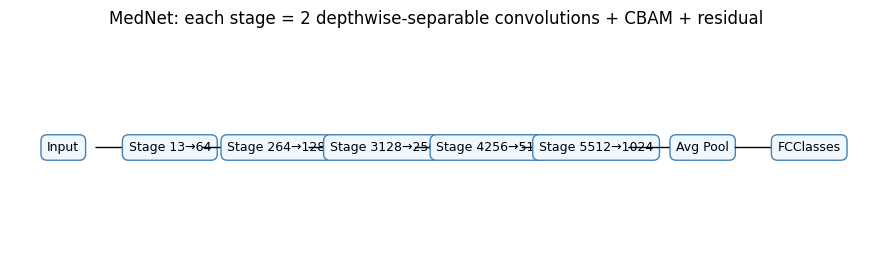

In [44]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.axis('off')
blocks = ['Input', 'Stage 1\
3→64', 'Stage 2\
64→128', 'Stage 3\
128→256',
          'Stage 4\
256→512', 'Stage 5\
512→1024', 'Avg Pool', 'FC\
Classes']
for i, label in enumerate(blocks):
    x = (i + .5) / len(blocks)
    ax.text(x, .5, label, ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round,pad=.5', facecolor='aliceblue', edgecolor='steelblue'))
    if i < len(blocks)-1:
        ax.annotate('', xy=((i+1.32)/len(blocks), .5),
                    xytext=((i+.78)/len(blocks), .5), arrowprops={'arrowstyle':'->'})
ax.set_title('MedNet: each stage = 2 depthwise-separable convolutions + CBAM + residual')
plt.savefig(os.path.join(OUTPUT_DIR, 'architecture.png'), dpi=150, bbox_inches='tight')
plt.show()

## Cell 9 — CPU runtime benchmark
Check the estimated cost of one batch before starting six runs. Benchmark numbers are estimates, not guarantees.

In [45]:
# demo_model = MedNet(8, True).to(DEVICE)
# x = torch.randn(BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE)
# y = torch.randint(0, 8, (BATCH_SIZE,))
# optimizer = torch.optim.AdamW(demo_model.parameters(), lr=3e-4)
# demo_model.train()
# t0 = time.perf_counter()
# optimizer.zero_grad()
# loss = F.cross_entropy(demo_model(x), y)
# loss.backward(); optimizer.step()
# train_batch_seconds = time.perf_counter() - t0
# demo_model.eval()
# t0 = time.perf_counter()
# with torch.no_grad(): demo_model(x)
# eval_batch_seconds = time.perf_counter() - t0
# print('Training batch:', round(train_batch_seconds, 2), 'seconds')
# print('Evaluation batch:', round(eval_batch_seconds, 2), 'seconds')
# for name in DATASETS:
#     count = len(SPLIT_INDICES[name]['train'])
#     val_count = len(SPLIT_INDICES[name]['val'])
#     estimate = EPOCHS * (np.ceil(count / BATCH_SIZE) * train_batch_seconds +
#                          np.ceil(val_count / BATCH_SIZE) * eval_batch_seconds) * 2 / 60
#     print(name, ': approximately', round(estimate, 1), 'minutes for both variants,', EPOCHS, 'epochs (rough estimate)')
# del demo_model, optimizer, x, y


## Cell 10 — Focal loss and training functions

In [46]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2):
        super().__init__()
        self.gamma = gamma
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce)
        return (((1 - pt) ** self.gamma) * ce).mean()

def one_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        if training:
            optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, correct / total

def train_one_dataset(name, variant, use_cbam):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    loaders = make_loaders(name)
    model = MedNet(len(all_data[name]['names']), use_cbam).to(DEVICE)
    criterion = FocalLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)
    history = []
    best_acc, waiting = -1, 0
    path = os.path.join(OUTPUT_DIR, name + '_' + variant + '_best.pt')
    start = time.time()
    for epoch in range(EPOCHS):
        train_loss, train_acc = one_epoch(model, loaders['train'], criterion, optimizer)
        val_loss, val_acc = one_epoch(model, loaders['val'], criterion)
        scheduler.step()
        history.append({'epoch':epoch+1, 'train_loss':train_loss, 'val_loss':val_loss,
                        'train_acc':train_acc, 'val_acc':val_acc})
        print(f'{name} {variant} | Epoch {epoch+1}/{EPOCHS} | train {train_acc:.3f} | val {val_acc:.3f} | {time.time()-start:.0f}s')
        if val_acc > best_acc:
            best_acc, waiting = val_acc, 0
            torch.save(model.state_dict(), path)
        else:
            waiting += 1
            if waiting >= PATIENCE:
                print('Early stopping')
                break
    pd.DataFrame(history).to_csv(os.path.join(OUTPUT_DIR, name + '_' + variant + '_history.csv'), index=False)
    model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=True))
    return model, loaders, pd.DataFrame(history), time.time()-start


## Cell 11 — Train all three datasets with and without CBAM
Each pair uses the same seed, data subset, optimizer, epoch limit and validation data. Each model has its own saved checkpoint. Set `RUN_TRAINING=True` in Cell 2 to begin.

In [47]:

models, histories, test_loaders, training_times = {}, {}, {}, {}
if RUN_TRAINING:
    for name in DATASETS:
        for variant, use_cbam in VARIANTS.items():
            print('\n==========', name.upper(), variant, '==========')
            model, loaders, history, duration = train_one_dataset(name, variant, use_cbam)
            key = (name, variant)
            models[key] = model
            histories[key] = history
            test_loaders[key] = loaders['test']
            training_times[key] = duration
else:
    print('Benchmark mode. Set RUN_TRAINING=True in Cell 2, then rerun the notebook to train.')



========== BLOODMNIST CBAM ==========
bloodmnist CBAM | Epoch 1/20 | train 0.847 | val 0.915 | 20s
bloodmnist CBAM | Epoch 2/20 | train 0.922 | val 0.946 | 41s
bloodmnist CBAM | Epoch 3/20 | train 0.947 | val 0.937 | 61s
bloodmnist CBAM | Epoch 4/20 | train 0.959 | val 0.965 | 81s
bloodmnist CBAM | Epoch 5/20 | train 0.973 | val 0.956 | 102s
bloodmnist CBAM | Epoch 6/20 | train 0.978 | val 0.967 | 122s
bloodmnist CBAM | Epoch 7/20 | train 0.984 | val 0.950 | 142s
bloodmnist CBAM | Epoch 8/20 | train 0.982 | val 0.935 | 162s
bloodmnist CBAM | Epoch 9/20 | train 0.989 | val 0.973 | 182s
bloodmnist CBAM | Epoch 10/20 | train 0.992 | val 0.966 | 203s
bloodmnist CBAM | Epoch 11/20 | train 0.995 | val 0.974 | 223s
bloodmnist CBAM | Epoch 12/20 | train 0.997 | val 0.973 | 243s
bloodmnist CBAM | Epoch 13/20 | train 0.998 | val 0.975 | 263s
bloodmnist CBAM | Epoch 14/20 | train 0.998 | val 0.980 | 283s
bloodmnist CBAM | Epoch 15/20 | train 0.999 | val 0.977 | 303s
bloodmnist CBAM | Epoch 16/20

## Cell 12 — Training and validation curves (paper-style figures)

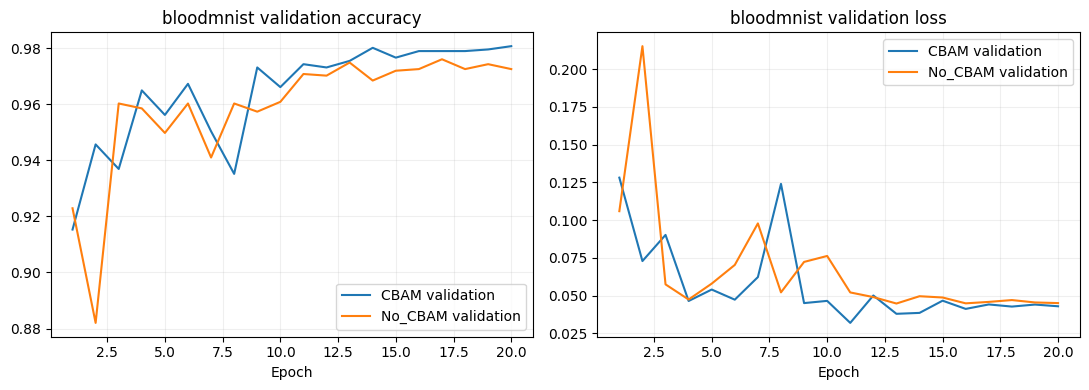

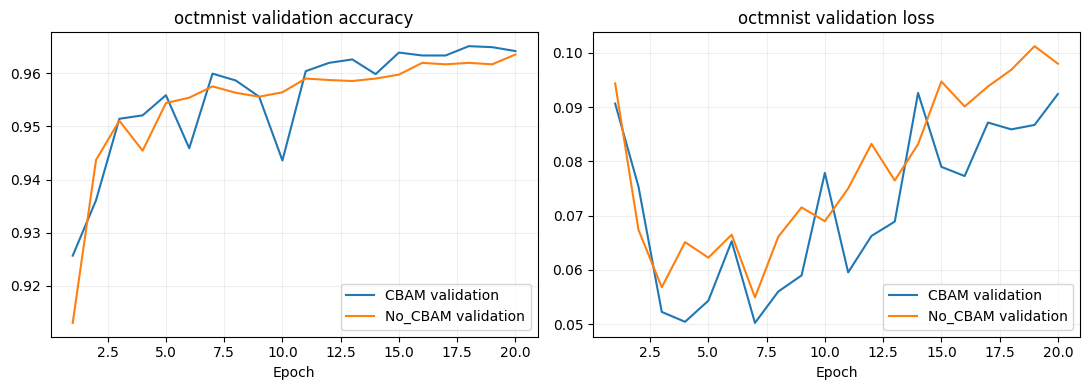

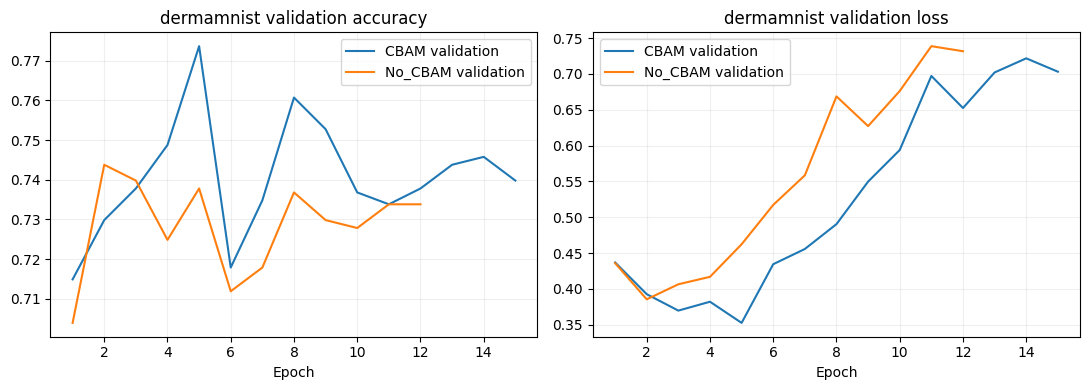

In [48]:
for name in DATASETS:
    if (name, 'CBAM') not in histories:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for variant in VARIANTS:
        h = histories[(name, variant)]
        axes[0].plot(h.epoch, h.val_acc, label=variant + ' validation')
        axes[1].plot(h.epoch, h.val_loss, label=variant + ' validation')
    axes[0].set_title(name + ' validation accuracy'); axes[0].set_xlabel('Epoch')
    axes[1].set_title(name + ' validation loss'); axes[1].set_xlabel('Epoch')
    for ax in axes: ax.legend(); ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, name + '_ablation_curves.png'), dpi=150)
    plt.show()


In [49]:
def predict_test(model, loader):
    model.eval()
    true, pred, probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(DEVICE))
            probabilities = torch.softmax(logits, dim=1).cpu().numpy()
            probs.append(probabilities)
            true.extend(labels.numpy())
            pred.extend(probabilities.argmax(axis=1))
    return np.asarray(true), np.asarray(pred), np.concatenate(probs)

predictions, rows = {}, []
for name in DATASETS:
    for variant in VARIANTS:
        key = (name, variant)
        if key not in models: continue
        y_true, y_pred, y_prob = predict_test(models[key], test_loaders[key])
        predictions[key] = (y_true, y_pred, y_prob)
        try:
            auc_score = roc_auc_score(y_true, y_prob, multi_class='ovr', labels=np.arange(y_prob.shape[1]))
        except ValueError:
            auc_score = np.nan
        rows.append({'Dataset':name, 'Variant':variant, 'Test N':len(y_true),
                     'Accuracy':accuracy_score(y_true, y_pred), 'AUC':auc_score,
                     'Macro F1':f1_score(y_true, y_pred, average='macro', zero_division=0),
                     'Macro Precision':precision_score(y_true, y_pred, average='macro', zero_division=0),
                     'Macro Recall':recall_score(y_true, y_pred, average='macro', zero_division=0),
                     'Train time (min)':training_times[key]/60})
results = pd.DataFrame(rows)
if len(results):
    print(results.round(4).to_string(index=False))
    results.to_csv(os.path.join(OUTPUT_DIR, 'all_results.csv'), index=False)
else:
    print('No trained models yet.')


   Dataset Variant  Test N  Accuracy    AUC  Macro F1  Macro Precision  Macro Recall  Train time (min)
bloodmnist    CBAM    3421    0.9775 0.9991    0.9779           0.9774        0.9784            6.7394
bloodmnist No_CBAM    3421    0.9702 0.9986    0.9718           0.9717        0.9720            4.7774
  octmnist    CBAM    1000    0.8450 0.9818    0.8416           0.8865        0.8450           55.2256
  octmnist No_CBAM    1000    0.8160 0.9743    0.8093           0.8818        0.8160           39.3821
dermamnist    CBAM    2005    0.7551 0.9248    0.5171           0.6514        0.5118            2.9494
dermamnist No_CBAM    2005    0.7207 0.8976    0.3748           0.4311        0.3656            1.6726


## Cell 13 — Evaluate all three models on held-out test data

## Cell 14 — Classification reports

In [50]:
for name in DATASETS:
    if (name, 'CBAM') not in predictions: continue
    y_true, y_pred, _ = predictions[(name, 'CBAM')]
    names = all_data[name]['names']
    report = classification_report(y_true, y_pred, labels=list(range(len(names))),
                                   target_names=names, zero_division=0)
    print('\n====', name.upper(), '====\n', report)
    with open(os.path.join(OUTPUT_DIR, name + '_classification_report.txt'), 'w') as f:
        f.write(report)


==== BLOODMNIST ====
                                                                      precision    recall  f1-score   support

                                                           basophil       0.98      0.97      0.98       244
                                                         eosinophil       1.00      1.00      1.00       624
                                                       erythroblast       1.00      0.99      0.99       311
immature granulocytes(myelocytes, metamyelocytes and promyelocytes)       0.94      0.95      0.94       579
                                                         lymphocyte       0.96      1.00      0.98       243
                                                           monocyte       0.96      0.96      0.96       284
                                                         neutrophil       0.97      0.97      0.97       666
                                                           platelet       1.00      1.00      1.00      

## Cell 15 — Confusion matrices

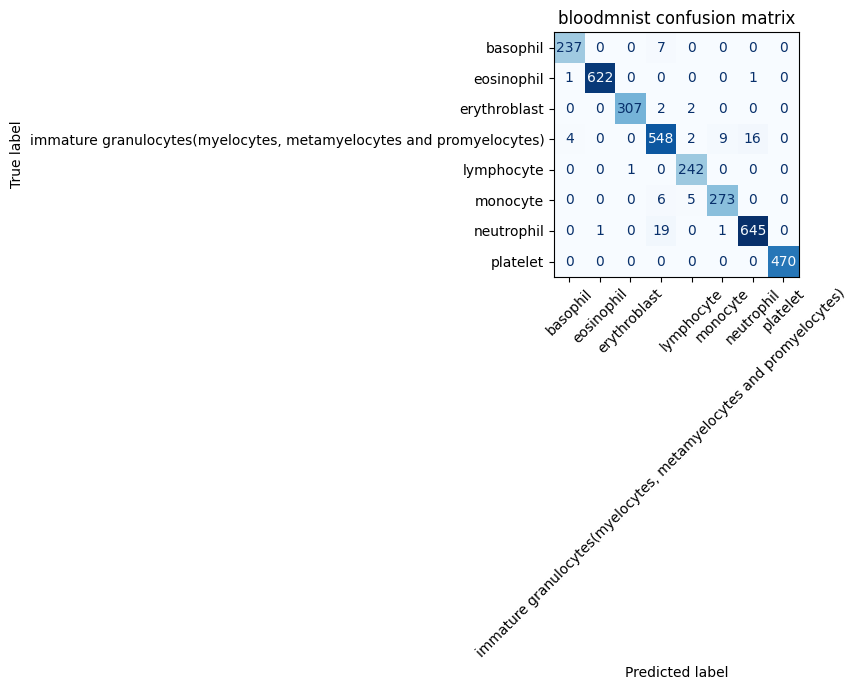

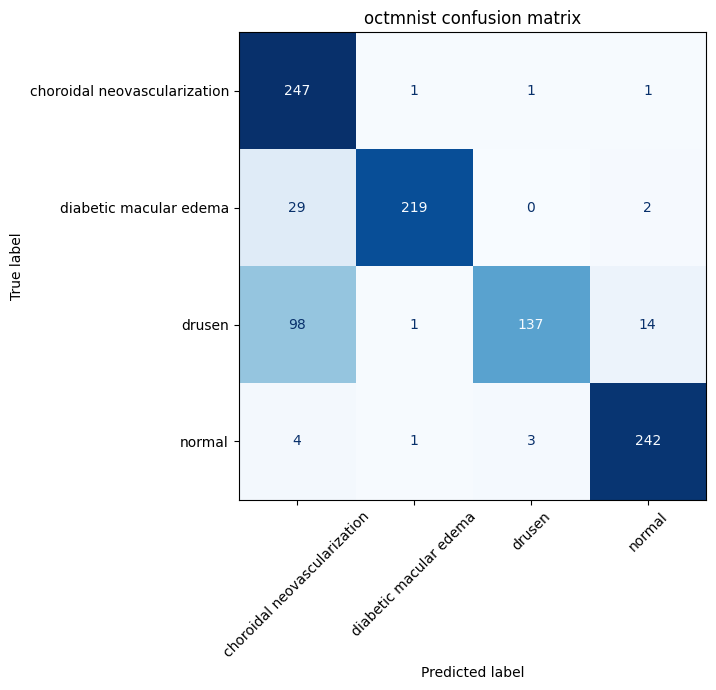

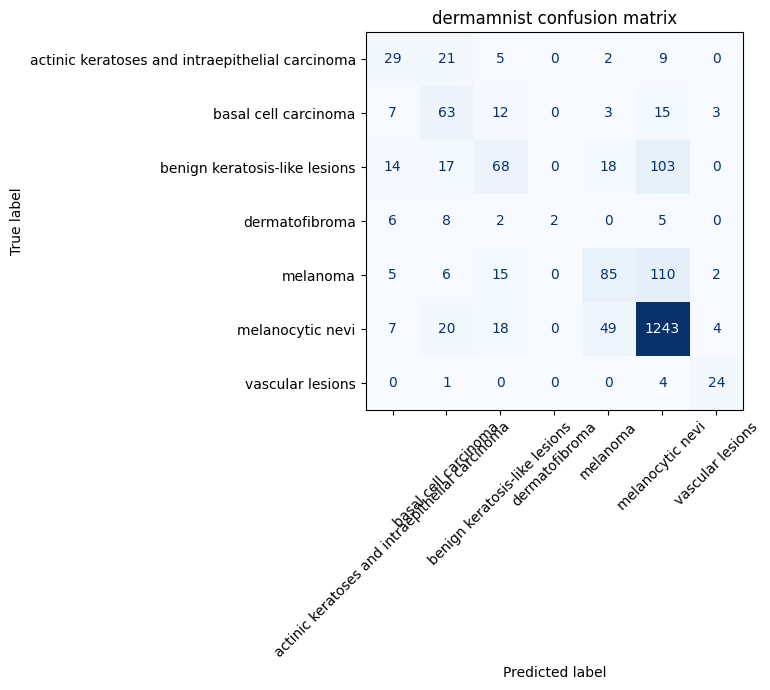

In [51]:
for name in DATASETS:
    if (name, 'CBAM') not in predictions: continue
    y_true, y_pred, _ = predictions[(name, 'CBAM')]
    names = all_data[name]['names']
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(names)))
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=ax, xticks_rotation=45,
                                                           cmap='Blues', colorbar=False)
    ax.set_title(name + ' confusion matrix')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, name + '_confusion.png'), dpi=150)
    plt.show()

## Cell 16 — ROC curves for each class

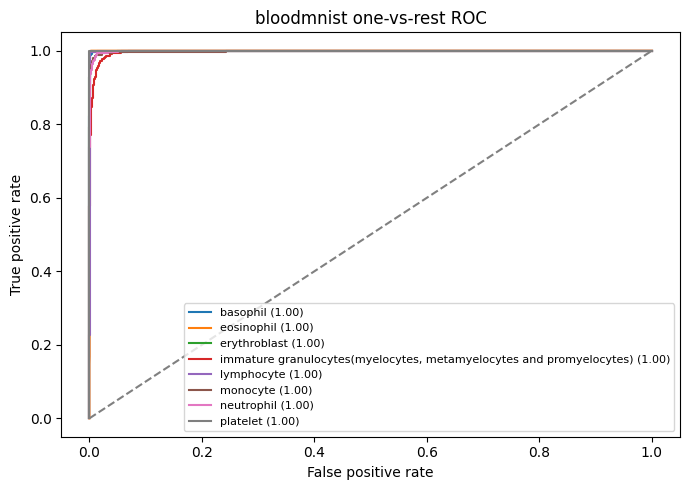

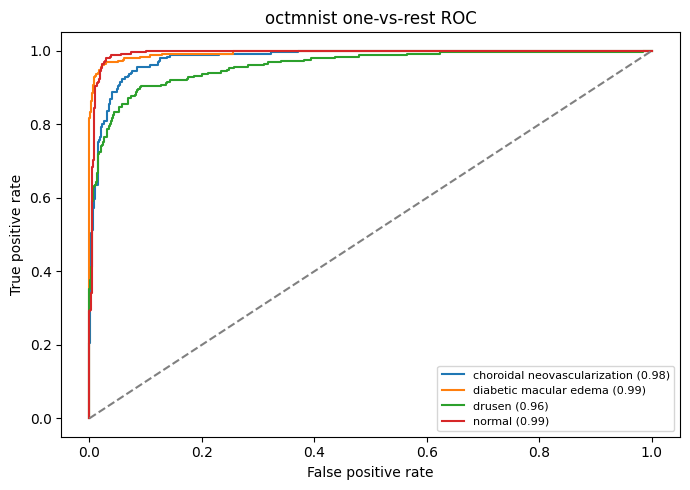

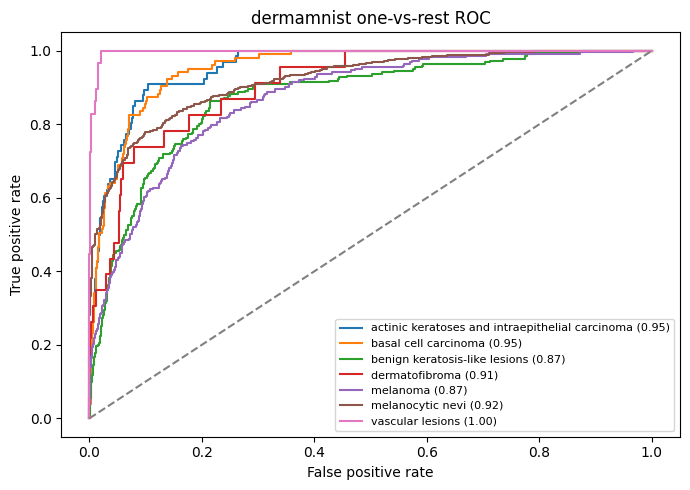

In [52]:
for name in DATASETS:
    if (name, 'CBAM') not in predictions: continue
    y_true, _, y_prob = predictions[(name, 'CBAM')]
    names = all_data[name]['names']
    fig, ax = plt.subplots(figsize=(7, 5))
    for k, label in enumerate(names):
        binary = (y_true == k).astype(int)
        if binary.min() == binary.max():
            continue
        fpr, tpr, _ = roc_curve(binary, y_prob[:, k])
        ax.plot(fpr, tpr, label=f'{label} ({auc(fpr,tpr):.2f})')
    ax.plot([0,1], [0,1], '--', color='gray')
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title(name + ' one-vs-rest ROC')
    ax.legend(fontsize=8, loc='lower right')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, name + '_roc.png'), dpi=150)
    plt.show()

## Cell 17 — Correct and incorrect test predictions

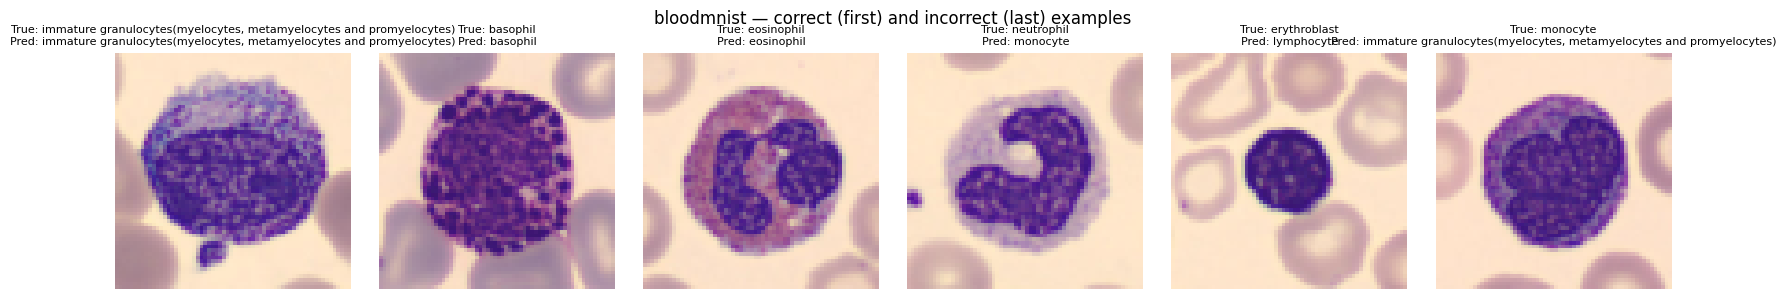

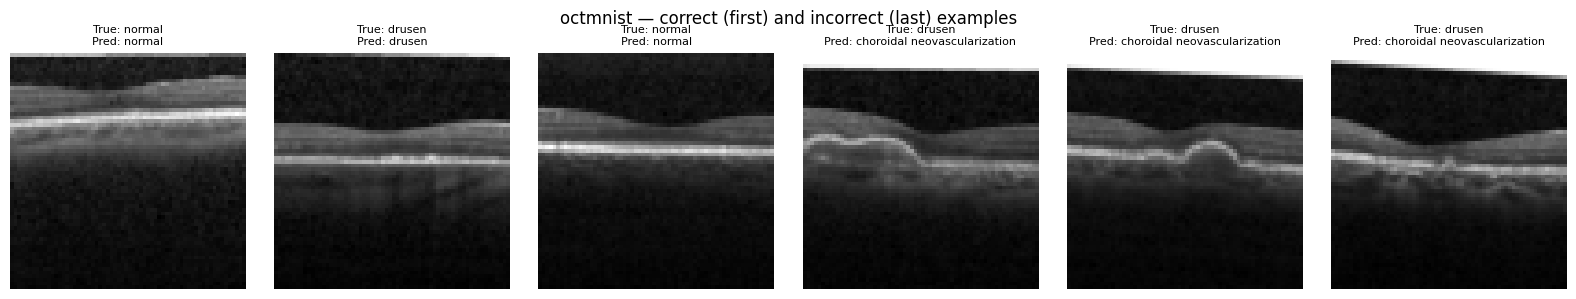

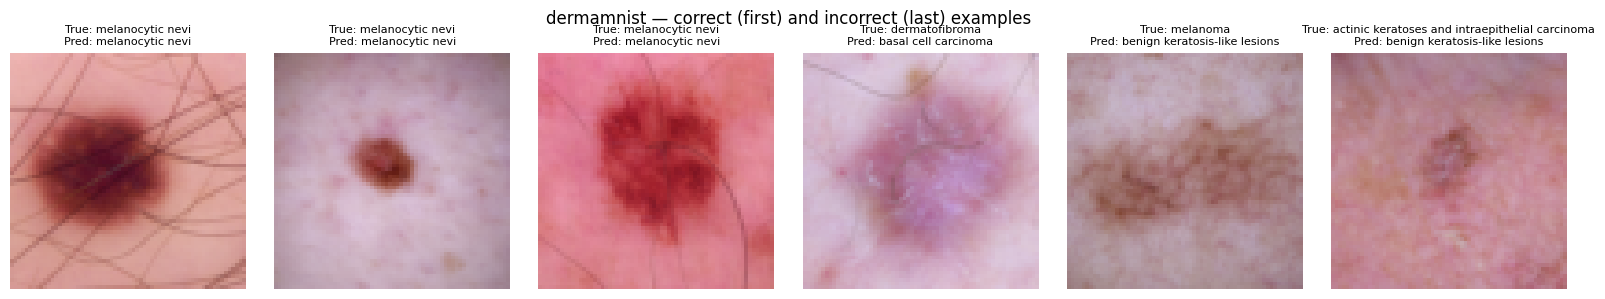

In [53]:
for name in DATASETS:
    if (name, 'CBAM') not in predictions: continue
    loader = test_loaders[(name, 'CBAM')]
    y_true, y_pred, y_prob = predictions[(name, 'CBAM')]
    ds = loader.dataset
    correct = np.flatnonzero(y_true == y_pred)
    wrong = np.flatnonzero(y_true != y_pred)
    indices = list(correct[:3]) + list(wrong[:3])
    fig, axes = plt.subplots(1, 6, figsize=(16, 3))
    for ax, idx in zip(axes, indices):
        image = ds.images[idx]
        ax.imshow(image, cmap='gray' if image.ndim == 2 else None)
        ax.set_title('True: '+all_data[name]['names'][y_true[idx]]+'\nPred: '+all_data[name]['names'][y_pred[idx]], fontsize=8)
        ax.axis('off')
    for ax in axes[len(indices):]: ax.axis('off')
    plt.suptitle(name + ' — correct (first) and incorrect (last) examples')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, name + '_examples.png'), dpi=150)
    plt.show()

## Cell 18 — Grad-CAM function (real gradients, not artificial heatmaps)\nShows heatmaps from each of the five stages. Grad-CAM highlights influential regions; it does not establish clinical reasoning.

In [54]:
def gradcam_for_stage(model, image_tensor, stage, class_id=None):
    saved = {}
    def forward_hook(module, inputs, output):
        saved['activation'] = output
        output.register_hook(lambda gradient: saved.update({'gradient':gradient}))
    handle = stage.register_forward_hook(forward_hook)
    model.eval()
    model.zero_grad(set_to_none=True)
    try:
        logits = model(image_tensor.unsqueeze(0).to(DEVICE))
        if class_id is None:
            class_id = int(logits.argmax(dim=1).item())
        logits[0, class_id].backward()
        activation = saved['activation'].detach()
        gradient = saved['gradient'].detach()
        weights = gradient.mean(dim=(2,3), keepdim=True)
        heatmap = (weights * activation).sum(dim=1, keepdim=True).relu()
        heatmap = F.interpolate(heatmap, size=image_tensor.shape[-2:], mode='bilinear', align_corners=False)
        heatmap = heatmap[0,0].cpu().numpy()
        heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
        return heatmap, class_id
    finally:
        handle.remove()

def show_gradcam(name, sample_index=0):
    model = models[(name, 'CBAM')]
    ds = test_loaders[(name, 'CBAM')].dataset
    x, true_label = ds[sample_index]
    original = ds.images[sample_index]
    stages = [model.stage1, model.stage2, model.stage3, model.stage4, model.stage5]
    fig, axes = plt.subplots(1, 6, figsize=(17, 3.4))
    axes[0].imshow(original, cmap='gray' if original.ndim==2 else None)
    axes[0].set_title('Original\nTrue: '+all_data[name]['names'][true_label], fontsize=8)
    axes[0].axis('off')
    predicted = None
    for i, stage in enumerate(stages):
        heatmap, predicted = gradcam_for_stage(model, x, stage)
        axes[i+1].imshow(original, cmap='gray' if original.ndim==2 else None)
        axes[i+1].imshow(heatmap, cmap='jet', alpha=0.45, vmin=0, vmax=1)
        axes[i+1].set_title('Grad-CAM Stage '+str(i+1), fontsize=9)
        axes[i+1].axis('off')
    fig.suptitle(name + ' | Predicted: ' + all_data[name]['names'][predicted])
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, name + '_gradcam_'+str(sample_index)+'.png'), dpi=150)
    plt.show()

## Cell 19 — Grad-CAM for all three datasets

Grad-CAM: bloodmnist


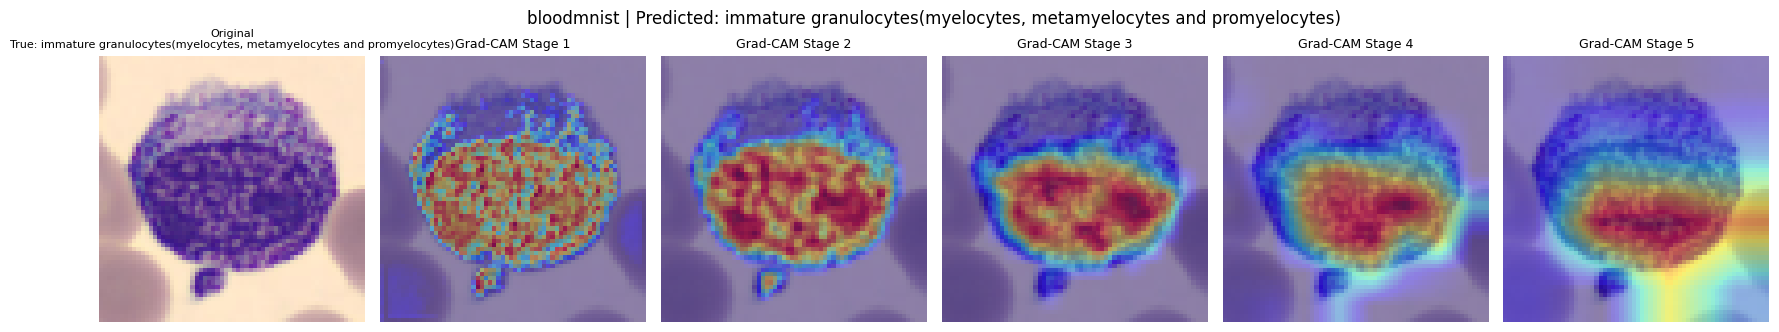

Grad-CAM: octmnist


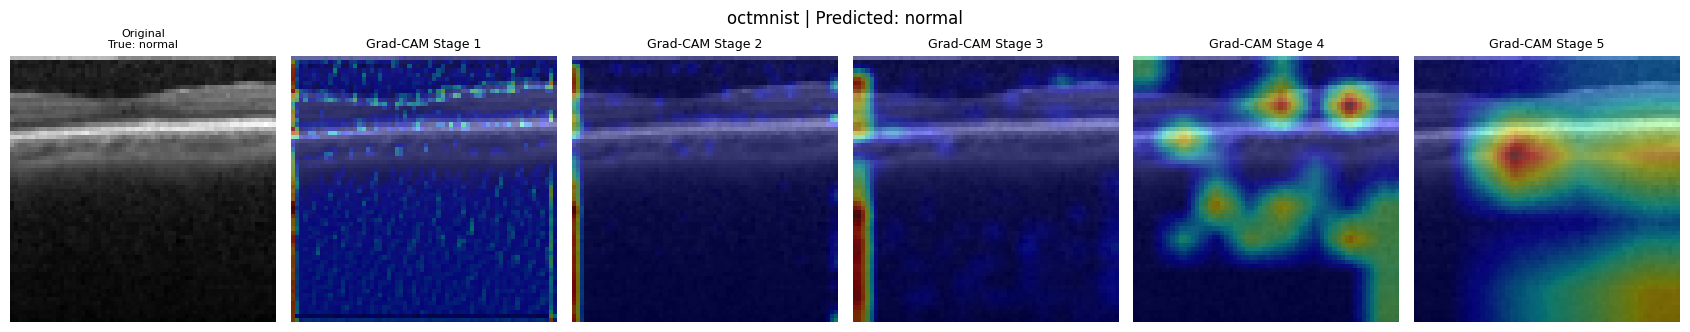

Grad-CAM: dermamnist


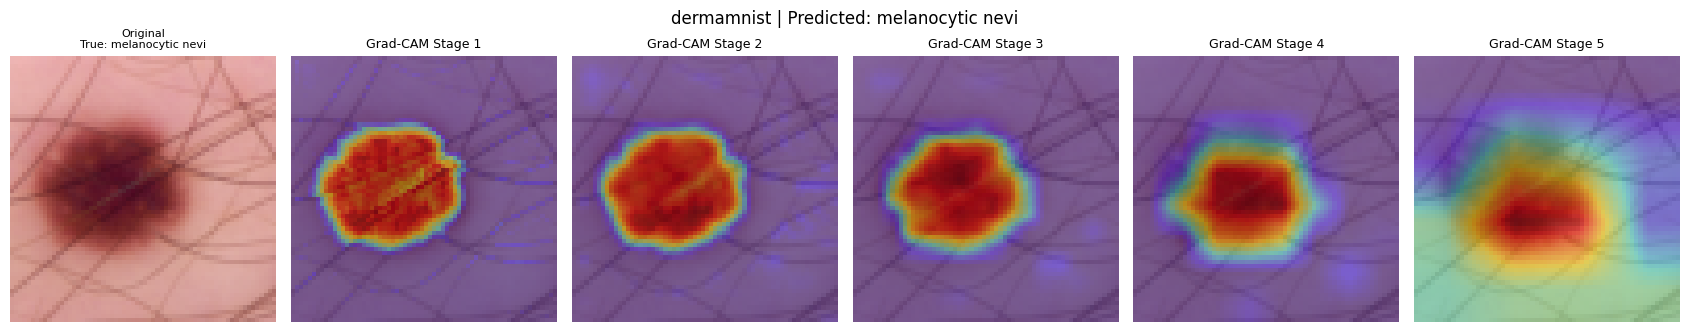

In [55]:
for name in DATASETS:
    print('Grad-CAM:', name)
    if (name, 'CBAM') in models: show_gradcam(name, sample_index=0)

## Cell 20 — DermaMNIST class imbalance analysis
Use the full official test split to examine minority-class recall and the normalized confusion matrix.

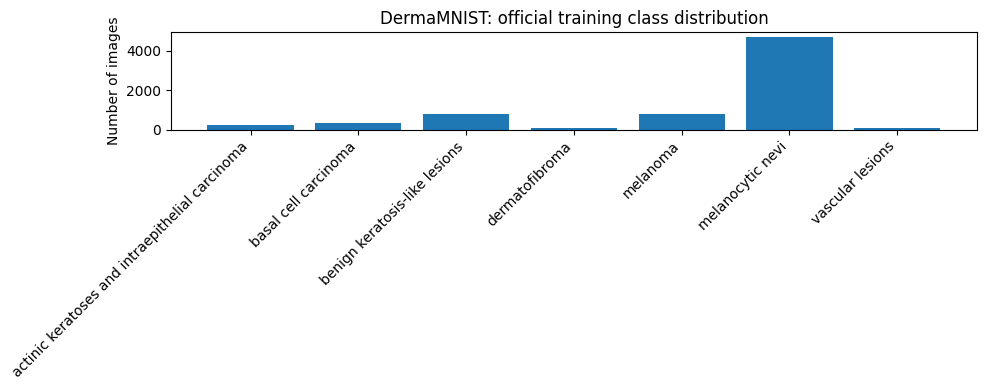

                                          Class  Train count  Test support  Precision  Recall    F1
actinic keratoses and intraepithelial carcinoma          228            66      0.426   0.439 0.433
                           basal cell carcinoma          359           103      0.463   0.612 0.527
                  benign keratosis-like lesions          769           220      0.567   0.309 0.400
                                 dermatofibroma           80            23      1.000   0.087 0.160
                                       melanoma          779           223      0.541   0.381 0.447
                               melanocytic nevi         4693          1341      0.835   0.927 0.878
                               vascular lesions           99            29      0.727   0.828 0.774


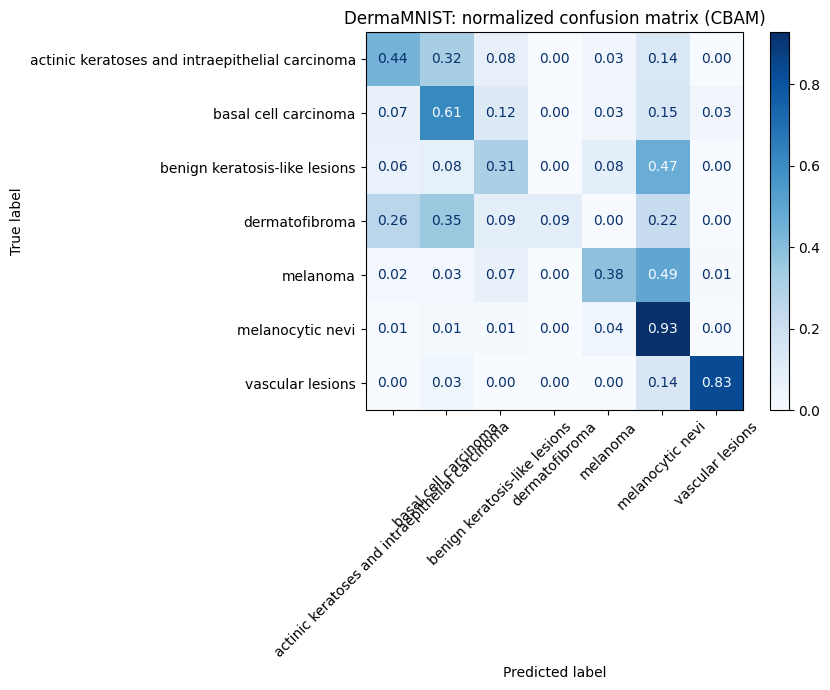

In [56]:
name = 'dermamnist'
train_labels = all_data[name]['splits']['train'][1].reshape(-1)
class_names = all_data[name]['names']
counts = np.bincount(train_labels, minlength=len(class_names))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(class_names, counts)
ax.set_title('DermaMNIST: official training class distribution')
ax.set_ylabel('Number of images')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'dermamnist_class_counts.png'), dpi=150)
plt.show()
if (name, 'CBAM') in predictions:
    true, pred, _ = predictions[(name, 'CBAM')]
    report = classification_report(true, pred, labels=np.arange(len(class_names)),
                                   target_names=class_names, zero_division=0, output_dict=True)
    analysis = pd.DataFrame([{'Class':label, 'Train count':int(counts[i]),
                              'Test support':int(report[label]['support']),
                              'Precision':report[label]['precision'],
                              'Recall':report[label]['recall'],
                              'F1':report[label]['f1-score']}
                             for i,label in enumerate(class_names)])
    print(analysis.round(3).to_string(index=False))
    analysis.to_csv(os.path.join(OUTPUT_DIR, 'dermamnist_per_class.csv'), index=False)
    cm = confusion_matrix(true, pred, labels=np.arange(len(class_names)), normalize='true')
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', values_format='.2f', xticks_rotation=45)
    ax.set_title('DermaMNIST: normalized confusion matrix (CBAM)')
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, 'dermamnist_normalized_confusion.png'), dpi=150)
    plt.show()


## Cell 21 — CBAM versus no-CBAM ablation
A controlled comparison with the same training budget. A single seed is informative but not statistically conclusive.

In [57]:
if len(results):
    table = results.pivot(index='Dataset', columns='Variant', values=['Accuracy','Macro F1','AUC'])
    print(table.round(4).to_string())
    for name in DATASETS:
        sub = results[results['Dataset'] == name].set_index('Variant')
        if {'CBAM','No_CBAM'}.issubset(sub.index):
            delta = 100 * (sub.loc['CBAM','Accuracy'] - sub.loc['No_CBAM','Accuracy'])
            print(f'{name}: CBAM minus No_CBAM = {delta:+.2f} accuracy percentage points')
else:
    print('Train both variants to view the ablation comparison.')


           Accuracy         Macro F1             AUC        
Variant        CBAM No_CBAM     CBAM No_CBAM    CBAM No_CBAM
Dataset                                                     
bloodmnist   0.9775  0.9702   0.9779  0.9718  0.9991  0.9986
dermamnist   0.7551  0.7207   0.5171  0.3748  0.9248  0.8976
octmnist     0.8450  0.8160   0.8416  0.8093  0.9818  0.9743
bloodmnist: CBAM minus No_CBAM = +0.73 accuracy percentage points
octmnist: CBAM minus No_CBAM = +2.90 accuracy percentage points
dermamnist: CBAM minus No_CBAM = +3.44 accuracy percentage points


## Cell 22 — Compare with published 28×28 results
These are **published reference accuracies**, not reproduced results. CPU subset training is not identical to the paper protocol.

In [58]:
paper_accuracy_28 = {'bloodmnist':0.961, 'octmnist':0.927, 'dermamnist':0.777}
if len(results):
    comparison = results.loc[results['Variant'] == 'CBAM', ['Dataset','Test N','Accuracy','AUC','Macro F1']].copy()
    comparison['Paper ACC (28x28)'] = comparison['Dataset'].map(paper_accuracy_28)
    comparison['ACC difference'] = comparison['Accuracy'] - comparison['Paper ACC (28x28)']
    print(comparison.round(4).to_string(index=False))
    comparison.to_csv(os.path.join(OUTPUT_DIR, 'paper_comparison.csv'), index=False)
else:
    print('Run training and evaluation first.')


   Dataset  Test N  Accuracy    AUC  Macro F1  Paper ACC (28x28)  ACC difference
bloodmnist    3421    0.9775 0.9991    0.9779              0.961          0.0165
  octmnist    1000    0.8450 0.9818    0.8416              0.927         -0.0820
dermamnist    2005    0.7551 0.9248    0.5171              0.777         -0.0219


## Cell 23 — Summary and saved outputs

In [59]:
print('MEDNET CPU REPRODUCTION SUMMARY')
print('Datasets:', ', '.join(DATASETS))
print('Full official test sets: YES')
print('Architecture: five-stage residual depthwise separable MedNet')
print('Resolution:', IMAGE_SIZE, '| Epoch limit:', EPOCHS)
print('Train limits:', TRAIN_LIMITS)
print('Variants:', ', '.join(VARIANTS))
if len(results):
    print(results.round(4).to_string(index=False))
    print('Saved results in:', OUTPUT_DIR)
else:
    print('Results will appear after training is enabled and completed.')


MEDNET CPU REPRODUCTION SUMMARY
Datasets: bloodmnist, octmnist, dermamnist
Full official test sets: YES
Architecture: five-stage residual depthwise separable MedNet
Resolution: 64 | Epoch limit: 20
Train limits: {'bloodmnist': None, 'octmnist': None, 'dermamnist': None}
Variants: CBAM, No_CBAM
   Dataset Variant  Test N  Accuracy    AUC  Macro F1  Macro Precision  Macro Recall  Train time (min)
bloodmnist    CBAM    3421    0.9775 0.9991    0.9779           0.9774        0.9784            6.7394
bloodmnist No_CBAM    3421    0.9702 0.9986    0.9718           0.9717        0.9720            4.7774
  octmnist    CBAM    1000    0.8450 0.9818    0.8416           0.8865        0.8450           55.2256
  octmnist No_CBAM    1000    0.8160 0.9743    0.8093           0.8818        0.8160           39.3821
dermamnist    CBAM    2005    0.7551 0.9248    0.5171           0.6514        0.5118            2.9494
dermamnist No_CBAM    2005    0.7207 0.8976    0.3748           0.4311        0.3656   

## Presentation guidance

Use your actual test metrics and figures. Explain the reduced training budgets and the difference between architectural reproduction and full experimental reproduction. Compare CBAM and no-CBAM, and discuss per-class recall on DermaMNIST. Do not claim that the paper results were reproduced unless your own measurements support that claim.

---
# NEW — Proposed novelty: Class-balanced MedNet (DermaMNIST)

**Everything above this section is unchanged.** This is an **additional experiment**, not a replacement for your original results.

**Question:** Can class-weighted focal loss improve minority-class recall and macro F1 on DermaMNIST while keeping the same MedNet + CBAM architecture?

We compare the **original CBAM + focal loss** against **CBAM + class-weighted focal loss**. The training subset, validation subset, architecture, seed, learning rate, and maximum epochs are unchanged. Only the loss function changes.

**Important:** This method is a proposed application of an existing technique, not a new loss function. Results are shown only after real training and full-test evaluation. The experiment may improve some classes and worsen others.

## Novelty Cell 1 — Check original baseline and calculate class weights

Weights are computed **only from the selected training subset**, never from test labels. We use inverse-square-root frequency, normalized to an average weight of 1, to avoid extremely large weights for rare classes.

In [60]:
NOVELTY_NAME = 'dermamnist'
NOVELTY_VARIANT = 'CBAM_Weighted_Focal'
NOVELTY_EPOCHS = EPOCHS
NOVELTY_PATIENCE = PATIENCE
RUN_NOVELTY = True  # Set False to skip the extra training run

novelty_names = all_data[NOVELTY_NAME]['names']
train_y = all_data[NOVELTY_NAME]['splits']['train'][1][SPLIT_INDICES[NOVELTY_NAME]['train']]
class_counts = np.bincount(train_y, minlength=len(novelty_names))
class_weights = 1.0 / np.power(np.maximum(class_counts, 1),0.25)
class_weights = class_weights / class_weights.mean()
print(class_weights)
print('Selected training images:', len(train_y))
print(pd.DataFrame({'Class': novelty_names,
                    'Training images': class_counts,
                    'Loss weight': class_weights.round(3)}).to_string(index=False))
print('Full test images:', len(all_data[NOVELTY_NAME]['splits']['test'][1]))
print('Baseline: original CBAM + focal loss; novelty: CBAM + weighted focal loss')

[1.09944762 0.98148721 0.81129103 1.42851814 0.80867477 0.5161734
 1.35440784]
Selected training images: 7007
                                          Class  Training images  Loss weight
actinic keratoses and intraepithelial carcinoma              228        1.099
                           basal cell carcinoma              359        0.981
                  benign keratosis-like lesions              769        0.811
                                 dermatofibroma               80        1.429
                                       melanoma              779        0.809
                               melanocytic nevi             4693        0.516
                               vascular lesions               99        1.354
Full test images: 2005
Baseline: original CBAM + focal loss; novelty: CBAM + weighted focal loss


## Novelty Cell 2 — Train MedNet using class-weighted focal loss

This trains **one additional DermaMNIST model** and saves it under a new filename. Your previous models, tables, and figures are not overwritten. This can take time on Kaggle CPU.

In [ ]:
class WeightedFocalLoss(nn.Module):
    def __init__(self, weights, gamma=2):
        super().__init__()
        self.register_buffer('weights', torch.tensor(weights, dtype=torch.float32))
        self.gamma = gamma

    def forward(self, logits, labels):
        ce = F.cross_entropy(logits, labels, reduction='none')
        pt = torch.exp(-ce)
        loss = self.weights[labels] * ((1 - pt) ** self.gamma) * ce
        return loss.mean()

novelty_model = None
novelty_history = None
novelty_loaders = None
novelty_path = os.path.join(OUTPUT_DIR, 'dermamnist_cbam_weighted_focal_best.pt')

if RUN_NOVELTY:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    novelty_loaders = make_loaders(NOVELTY_NAME)
    novelty_model = MedNet(len(novelty_names), use_cbam=True).to(DEVICE)
    novelty_loss = WeightedFocalLoss(class_weights).to(DEVICE)
    novelty_optimizer = torch.optim.AdamW(novelty_model.parameters(), lr=3e-4, weight_decay=1e-4)
    novelty_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(novelty_optimizer, T_max=20, eta_min=1e-6)
    novelty_records = []
    best_val, waiting = -1, 0
    start = time.time()

    for epoch in range(NOVELTY_EPOCHS):
        train_loss, train_acc = one_epoch(novelty_model, novelty_loaders['train'], novelty_loss, novelty_optimizer)
        val_loss, val_acc = one_epoch(novelty_model, novelty_loaders['val'], novelty_loss)
        novelty_scheduler.step()
        novelty_records.append({'epoch': epoch+1, 'train_loss': train_loss,
                                'val_loss': val_loss, 'train_acc': train_acc, 'val_acc': val_acc})
        print(f'Weighted focal | Epoch {epoch+1}/{NOVELTY_EPOCHS} | '
              f'train acc {train_acc:.3f} | val acc {val_acc:.3f} | '
              f'time {time.time()-start:.0f}s')
        if val_acc > best_val:
            best_val, waiting = val_acc, 0
            torch.save(novelty_model.state_dict(), novelty_path)
        else:
            waiting += 1
            if waiting >= NOVELTY_PATIENCE:
                print('Early stopping')
                break

    novelty_history = pd.DataFrame(novelty_records)
    novelty_history.to_csv(os.path.join(OUTPUT_DIR, 'dermamnist_weighted_focal_history.csv'), index=False)
    novelty_model.load_state_dict(torch.load(novelty_path, map_location=DEVICE, weights_only=True))
    print('Saved novelty model:', novelty_path)
else:
    print('Novelty training skipped. Set RUN_NOVELTY=True to train the additional model.')

Weighted focal | Epoch 1/20 | train acc 0.628 | val acc 0.703 | time 12s
Weighted focal | Epoch 2/20 | train acc 0.691 | val acc 0.729 | time 24s
Weighted focal | Epoch 3/20 | train acc 0.716 | val acc 0.726 | time 36s
Weighted focal | Epoch 4/20 | train acc 0.741 | val acc 0.722 | time 48s
Weighted focal | Epoch 5/20 | train acc 0.758 | val acc 0.742 | time 59s
Weighted focal | Epoch 6/20 | train acc 0.792 | val acc 0.692 | time 71s
Weighted focal | Epoch 7/20 | train acc 0.829 | val acc 0.718 | time 83s
Weighted focal | Epoch 8/20 | train acc 0.867 | val acc 0.732 | time 95s
Weighted focal | Epoch 9/20 | train acc 0.913 | val acc 0.734 | time 106s
Weighted focal | Epoch 10/20 | train acc 0.948 | val acc 0.725 | time 118s
Weighted focal | Epoch 11/20 | train acc 0.966 | val acc 0.728 | time 130s
Weighted focal | Epoch 12/20 | train acc 0.981 | val acc 0.743 | time 142s
Weighted focal | Epoch 13/20 | train acc 0.989 | val acc 0.723 | time 154s
Weighted focal | Epoch 14/20 | train acc 0

## Novelty Cell 3 — Compare original and proposed method on the FULL test set

The comparison uses your previously trained original CBAM checkpoint when available. The test set is not used for model selection. If the baseline checkpoint is missing, the notebook tells you rather than inventing numbers.

In [ ]:
novelty_comparison = pd.DataFrame()
novelty_predictions = {}

if novelty_model is not None:
    baseline_key = (NOVELTY_NAME, 'CBAM')
    baseline_model = models.get(baseline_key) if 'models' in globals() else None
    baseline_path = os.path.join(OUTPUT_DIR, 'dermamnist_CBAM_best.pt')
    if baseline_model is None and os.path.isfile(baseline_path):
        baseline_model = MedNet(len(novelty_names), use_cbam=True).to(DEVICE)
        baseline_model.load_state_dict(torch.load(baseline_path, map_location=DEVICE, weights_only=True))

    if baseline_model is None:
        print('Original CBAM baseline not found. Run the earlier training cells or restore its checkpoint.')
    else:
        full_test_loader = novelty_loaders['test']
        baseline_true, baseline_pred, baseline_prob = predict_test(baseline_model, full_test_loader)
        weighted_true, weighted_pred, weighted_prob = predict_test(novelty_model, full_test_loader)
        assert np.array_equal(baseline_true, weighted_true)
        assert len(weighted_true) == len(all_data[NOVELTY_NAME]['splits']['test'][1])

        novelty_predictions = {
            'Original focal loss': (baseline_true, baseline_pred, baseline_prob),
            'Weighted focal loss': (weighted_true, weighted_pred, weighted_prob)
        }
        comparison_rows = []
        for method, (y_true, y_pred, y_prob) in novelty_predictions.items():
            try:
                auc_value = roc_auc_score(y_true, y_prob, multi_class='ovr',
                                          labels=np.arange(len(novelty_names)))
            except ValueError:
                auc_value = np.nan
            comparison_rows.append({'Method': method, 'Test images': len(y_true),
                                    'Accuracy': accuracy_score(y_true, y_pred),
                                    'Macro F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
                                    'Macro recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
                                    'AUC': auc_value})
        novelty_comparison = pd.DataFrame(comparison_rows)
        print(novelty_comparison.round(4).to_string(index=False))
        novelty_comparison.to_csv(os.path.join(OUTPUT_DIR, 'octmnist_novelty_comparison.csv'), index=False)
        delta_f1 = novelty_comparison.iloc[1]['Macro F1'] - novelty_comparison.iloc[0]['Macro F1']
        print(f'Change in macro F1: {delta_f1:+.4f} (weighted minus original)')
else:
    print('Run Novelty Cell 2 first to obtain genuine test results.')

             Method  Test images  Accuracy  Macro F1  Macro recall    AUC
Original focal loss         2005    0.7551    0.5171        0.5118 0.9248
Weighted focal loss         2005    0.7536    0.5507        0.5239 0.9124
Change in macro F1: +0.0336 (weighted minus original)


## Novelty Cell 4 — Show which classes improved (or became worse)

This is the most useful novelty figure for your presentation. **A negative change is still a valid finding.**

                                          Class  Original recall  Weighted recall  Change
actinic keratoses and intraepithelial carcinoma            0.439            0.455   0.015
                           basal cell carcinoma            0.612            0.524  -0.087
                  benign keratosis-like lesions            0.309            0.418   0.109
                                 dermatofibroma            0.087            0.261   0.174
                                       melanoma            0.381            0.413   0.031
                               melanocytic nevi            0.927            0.908  -0.019
                               vascular lesions            0.828            0.690  -0.138


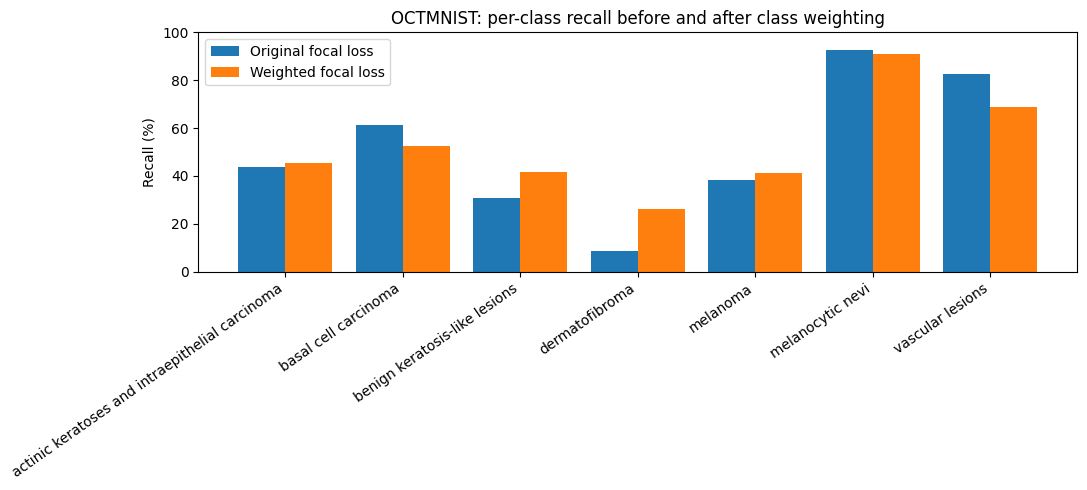

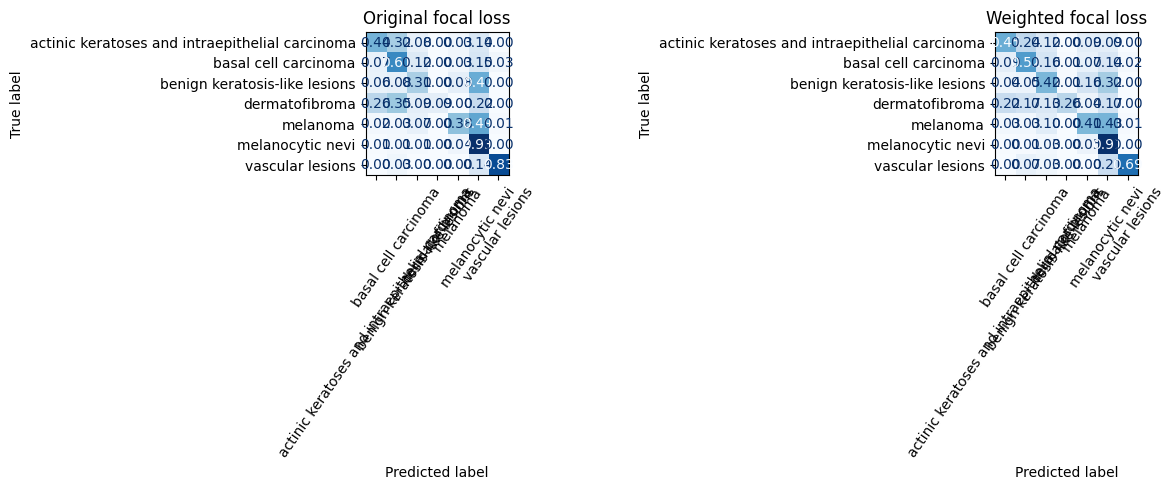

In [ ]:
if novelty_predictions:
    labels = np.arange(len(novelty_names))
    original_true, original_pred, _ = novelty_predictions['Original focal loss']
    weighted_true, weighted_pred, _ = novelty_predictions['Weighted focal loss']
    original_recall = recall_score(original_true, original_pred, labels=labels,
                                   average=None, zero_division=0)
    weighted_recall = recall_score(weighted_true, weighted_pred, labels=labels,
                                   average=None, zero_division=0)
    recall_table = pd.DataFrame({
        'Class': novelty_names,
        'Original recall': original_recall,
        'Weighted recall': weighted_recall,
        'Change': weighted_recall - original_recall
    })
    print(recall_table.round(3).to_string(index=False))
    recall_table.to_csv(os.path.join(OUTPUT_DIR, 'dermamnist_novelty_class_recall.csv'), index=False)

    positions = np.arange(len(novelty_names))
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.bar(positions - 0.2, original_recall * 100, width=0.4, label='Original focal loss')
    ax.bar(positions + 0.2, weighted_recall * 100, width=0.4, label='Weighted focal loss')
    ax.set_xticks(positions)
    ax.set_xticklabels(novelty_names, rotation=35, ha='right')
    ax.set_ylim(0, 100)
    ax.set_ylabel('Recall (%)')
    ax.set_title('OCTMNIST: per-class recall before and after class weighting')
    ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'dermamnist_novelty_recall.png'), dpi=160)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, method in zip(axes, novelty_predictions):
        y_true, y_pred, _ = novelty_predictions[method]
        matrix = confusion_matrix(y_true, y_pred, labels=labels, normalize='true')
        ConfusionMatrixDisplay(matrix, display_labels=novelty_names).plot(
            ax=ax, cmap='Blues', values_format='.2f', xticks_rotation=55, colorbar=False)
        ax.set_title(method)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'octmnist_novelty_confusion_matrices.png'), dpi=160)
    plt.show()
else:
    print('No novelty predictions yet. Complete the training and comparison cells above.')

## How to explain this novelty in your presentation

> **My proposed improvement** was to make MedNet more class-aware without changing its architecture. I used class-weighted focal loss, calculated from the training class distribution, and compared it with the original focal loss on the full DermaMNIST test set. I focused on macro F1 and minority-class recall because overall accuracy can hide poor performance on rare classes.

**Report the actual numbers printed above.** If weighted focal loss does not improve macro F1 or minority recall, explain that the hypothesis was not supported under this training setup. A single training seed is not sufficient to prove consistent improvement. Do not call this a new loss function or a clinically validated improvement.

In [64]:
from datetime import datetime
from zoneinfo import ZoneInfo
from pathlib import Path

now_pkt = lambda: datetime.now(ZoneInfo('Asia/Karachi')).strftime('%Y-%m-%d %H:%M:%S PKT')

print('=' * 55)
print('MEDNET — NEW TIMESTAMPED TEST EVALUATION')
print('Evaluation started:', now_pkt())
print('=' * 55)

new_log = ['MedNet — timestamped evaluation', 'Started: ' + now_pkt()]

if 'models' not in globals() or 'test_loaders' not in globals() or 'predict_test' not in globals():
    print('Models or test loaders are not loaded. Run the model setup/evaluation cells first.')
else:
    from sklearn.metrics import accuracy_score, f1_score
    for dataset_name in DATASETS:
        key = (dataset_name, 'CBAM')
        if key not in models or key not in test_loaders:
            print('Skipping', dataset_name, '— trained model/test loader unavailable')
            continue
        print('Evaluating:', dataset_name, '| Time:', now_pkt())
        y_true, y_pred, _ = predict_test(models[key], test_loaders[key])
        line = (f'{dataset_name}: test_n={len(y_true)}, '
                f'accuracy={accuracy_score(y_true, y_pred):.4f}, '
                f'macro_f1={f1_score(y_true, y_pred, average="macro", zero_division=0):.4f}')
        print(line)
        new_log.append(line)

new_log.append('Finished: ' + now_pkt())
print('Evaluation finished:', now_pkt())

out_dir = Path(OUTPUT_DIR if 'OUTPUT_DIR' in globals() else '/kaggle/working')
out_dir.mkdir(parents=True, exist_ok=True)
new_path = out_dir / 'mednet_timestamped_evaluation_log.txt'
new_path.write_text('\n'.join(new_log), encoding='utf-8')
print('Saved:', new_path)


MEDNET — NEW TIMESTAMPED TEST EVALUATION
Evaluation started: 2026-11-26 01:41:04 PKT
Evaluating: bloodmnist | Time: 2026-11-26 01:41:04 PKT
bloodmnist: test_n=3421, accuracy=0.9775, macro_f1=0.9779
Evaluating: octmnist | Time: 2026-11-26 01:41:05 PKT
octmnist: test_n=1000, accuracy=0.8450, macro_f1=0.8416
Evaluating: dermamnist | Time: 2026-11-26 01:41:06 PKT
dermamnist: test_n=2005, accuracy=0.7551, macro_f1=0.5171
Evaluation finished: 2026-11-26 01:41:06 PKT
Saved: /kaggle/working/mednet_64_results/mednet_timestamped_evaluation_log.txt


In [65]:
import shutil, os
from pathlib import Path
from IPython.display import FileLink, display

src = Path("/kaggle/working/mednet_results")
dst = Path("/kaggle/working/models")
shutil.rmtree(dst, ignore_errors=True)
dst.mkdir()
for pt in sorted(src.glob("*.pt")):
    shutil.copy(pt, dst / pt.name)
    print("packed", pt.name, f"{pt.stat().st_size/1e6:.1f} MB")

out = shutil.make_archive("/kaggle/working/models", "zip", "/kaggle/working", "models")
print("Ready:", out, f"({os.path.getsize(out)/1e6:.1f} MB)")
display(FileLink("models.zip"))

packed bloodmnist_CBAM_best.pt 13.2 MB
packed bloodmnist_No_CBAM_best.pt 12.5 MB
packed dermamnist_CBAM_best.pt 13.2 MB
packed dermamnist_No_CBAM_best.pt 12.5 MB
packed dermamnist_cbam_weighted_focal_best.pt 13.2 MB
packed octmnist_CBAM_best.pt 13.2 MB
packed octmnist_No_CBAM_best.pt 12.5 MB
Ready: /kaggle/working/models.zip (83.1 MB)


/kaggle/working/models.zip